In [2]:
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import numpy as np
import torch.nn as nn 
import matplotlib.pyplot as plt
import seaborn as sns
import os
import random

In [2]:
import sys
from pathlib import Path

# Detect the project root without changing the working directory.
current_dir = Path.cwd().resolve()

if (current_dir / "scripts").is_dir():
    PROJECT_ROOT = current_dir

elif (
    current_dir.name == "notebooks"
    and (current_dir.parent / "scripts").is_dir()
):
    PROJECT_ROOT = current_dir.parent

else:
    raise FileNotFoundError(
        "Could not locate the project root. "
        "Launch Jupyter from the project root or notebooks/."
    )

SCRIPTS_DIR = PROJECT_ROOT / "scripts"
DATA_DIR = PROJECT_ROOT / "data"
PRIVATE_DIR = PROJECT_ROOT / "sensitive_info"

if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from metadata_fetcher import MetadataTracker

MASTER_DB = DATA_DIR / "master_track_table.csv"
HISTORY_DB = PRIVATE_DIR / "spotify_listening_history.csv"

print(f"Project root: {PROJECT_ROOT}")
print(f"Master DB exists: {MASTER_DB.exists()}")
print(f"History exists: {HISTORY_DB.exists()}")


Project root: D:\BetterSpotifyShuffle
Master DB exists: True
History exists: True


In [3]:
MODEL_FEATURES = [
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature"
]

NUM_AUDIO_FEATURES = len(MODEL_FEATURES)

NUM_FEATURES = NUM_AUDIO_FEATURES * 2


class SpotifySequenceDataset(Dataset):
    
    def __init__(self, history_csv, master_db_csv, max_seq_length=10, mode="nip"):
        if mode not in ("nip", "dpo"):
            raise ValueError("mode must be 'nip' or 'dpo'")

        self.max_seq_length = max_seq_length
        self.mode = mode

        self.feature_lookup = self._build_feature_dict(
            master_db_csv
        )

        self.all_track_ids = [
            track_id
            for track_id in self.feature_lookup
            if self.has_observed_features(track_id)
        ]

        history_df = pd.read_csv(
            history_csv,
            low_memory=False
        )

        print("\nListening event distribution:")
        print(
            history_df["event_type"].value_counts(
                dropna=False
            )
        )

        sessions = self._chunk_sessions(history_df)

        nip_data, dpo_data = self._extract_training_data(
            sessions
        )

        self.data = (
            dpo_data if mode == "dpo"
            else nip_data
        )

        print(
            f"Dataset initialized in {mode.upper()} mode "
            f"with {len(self.data)} examples."
        )


    def _build_feature_dict(self, master_db_csv):
        """Build track vectors with audio features and availability masks."""

        print("Loading Master DB and processing features...")

        df = pd.read_csv(master_db_csv, low_memory=False)

        if "id" not in df.columns:
            raise ValueError("Master DB must contain an 'id' column.")

        missing_columns = [
            col for col in MODEL_FEATURES
            if col not in df.columns
        ]

        if missing_columns:
            raise ValueError(
                f"Missing feature columns: {missing_columns}"
            )

        # Normalize Spotify track identifiers.
        df["id"] = df["id"].astype("string").str.strip()
        df = df.dropna(subset=["id"])
        df = df[df["id"] != ""]
        df = df.drop_duplicates(subset=["id"])

        # Work only with the features currently used by the model.
        features = df[MODEL_FEATURES].copy()

        for col in MODEL_FEATURES:
            features[col] = pd.to_numeric(
                features[col],
                errors="coerce"
            )

        # Support old database records using -1 for unknowns.
        # Bounded features: -1 is not a valid measurement.
        bounded_features = [
            "danceability", "energy", "speechiness",
            "acousticness", "instrumentalness",
            "liveness", "valence"
        ]

        for col in bounded_features:
            features.loc[
                ~features[col].between(0.0, 1.0),
                col
            ] = np.nan

        # Discrete audio properties
        features.loc[
            ~features["key"].isin(range(12)),
            "key"
        ] = np.nan

        features.loc[
            ~features["mode"].isin([0, 1]),
            "mode"
        ] = np.nan

        features.loc[
            (features["time_signature"] <= 0)
            | (features["time_signature"] % 1 != 0),
            "time_signature"
        ] = np.nan

        # Negative tempo is invalid; zero may indicate no detected beat.
        features.loc[
            features["tempo"] < 0,
            "tempo"
        ] = np.nan

        # 1 = observed, 0 = missing.
        availability_mask = (
            features.notna().to_numpy(dtype=np.float32)
        )

        print("Feature availability:")
        for col, rate in zip(
            MODEL_FEATURES,
            availability_mask.mean(axis=0)
        ):
            print(f"  {col}: {rate:.1%}")

        # Scale observed values only.
        self.scalers = {}

        for col in ["loudness", "tempo"]:
            valid = features[col].notna()

            if not valid.any():
                continue

            scaler = MinMaxScaler()

            features.loc[valid, col] = (
                scaler.fit_transform(
                    features.loc[valid, [col]]
                ).ravel()
            )

            self.scalers[col] = scaler

        # Missing numerical values are replaced only AFTER
        # their availability has been recorded.
        features = features.fillna(0.0)

        audio_matrix = features.to_numpy(
            dtype=np.float32
        )

        # Combine actual feature values with their availability.
        features_matrix = np.concatenate(
            [audio_matrix, availability_mask],
            axis=1
        )

        feature_lookup = {
            str(track_id): torch.from_numpy(feature_vector)
            for track_id, feature_vector in zip(
                df["id"],
                features_matrix
            )
        }

        print(
            f"Built feature dictionary for "
            f"{len(feature_lookup)} tracks."
        )

        print(
            f"Feature dimensions per track: "
            f"{features_matrix.shape[1]}"
        )

        return feature_lookup


    def _chunk_sessions(self, history_df):
        """Group chronological listening events into sessions."""

        df = history_df.copy()

        required = ["timestamp", "track_id", "event_type"]

        missing = [
            col for col in required
            if col not in df.columns
        ]

        if missing:
            raise ValueError(
                f"Missing history columns: {missing}"
            )

        df["timestamp"] = pd.to_datetime(
            df["timestamp"],
            utc=True,
            errors="coerce",
            format="mixed"
        )

        df["track_id"] = (
            df["track_id"].astype("string").str.strip()
        )

        df = df.dropna(
            subset=["timestamp", "track_id"]
        )

        df = df[df["track_id"] != ""]

        df = df.sort_values(
            "timestamp",
            kind="stable"
        ).reset_index(drop=True)

        time_gaps = df["timestamp"].diff()

        new_session = (
            time_gaps.isna()
            | (time_gaps > pd.Timedelta(minutes=20))
        )

        df["session_id"] = new_session.cumsum()

        sessions = [
            group
            for _, group in df.groupby(
                "session_id",
                sort=False
            )
        ]

        print(
            f"Divided {len(df)} listening events "
            f"into {len(sessions)} sessions."
        )

        return sessions

    
    def _extract_training_data(self, sessions):
        """Extract next-item and pairwise preference examples."""

        nip_dataset = []
        preference_dataset = []

        for session_df in sessions:
            current_context = []
            pending_negatives = []

            for row in session_df.itertuples():
                track_id = str(row.track_id)
                event_type = row.event_type

                # Tracks without usable features cannot provide
                # meaningful inputs or targets.
                if not self.has_observed_features(track_id):
                    current_context = []
                    pending_negatives = []
                    continue

                if event_type == "GHOST_SKIP":
                    pending_negatives.append(track_id)

                elif event_type == "PLAY":

                    if current_context:
                        nip_dataset.append({
                            "context": list(current_context),
                            "target": track_id,
                            "timestamp": row.timestamp
                        })

                        for negative_track in pending_negatives:
                            if negative_track != track_id:
                                preference_dataset.append({
                                    "context": list(current_context),
                                    "positive": track_id,
                                    "negative": negative_track,
                                    "timestamp": row.timestamp
                                })

                    pending_negatives = []

                    current_context.append(track_id)

                    if len(current_context) > self.max_seq_length:
                        current_context.pop(0)

                else:
                    # Neutral interactions break this sequence.
                    current_context = []
                    pending_negatives = []

        print(
            f"Extracted {len(nip_dataset)} "
            f"next-item prediction examples."
        )

        print(
            f"Extracted {len(preference_dataset)} "
            f"preference pairs."
        )

        return nip_dataset, preference_dataset

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data[idx]

        context_ids = sample["context"][-self.max_seq_length:]
        seq_len = len(context_ids)

        context_tensor = torch.zeros(
            (self.max_seq_length, NUM_FEATURES),
            dtype=torch.float32
        )

        padding_mask = torch.ones(
            self.max_seq_length,
            dtype=torch.bool
        )

        start_idx = self.max_seq_length - seq_len

        for i, track_id in enumerate(context_ids):
            position = start_idx + i

            context_tensor[position] = (
                self.feature_lookup[track_id]
            )

            padding_mask[position] = False

        if self.mode == "dpo":
            positive_id = sample["positive"]
            negative_id = sample["negative"]

        else:
            positive_id = sample["target"]

            negative_id = random.choice(
                self.all_track_ids
            )

            while (
                negative_id == positive_id
                or negative_id in context_ids
            ):
                negative_id = random.choice(
                    self.all_track_ids
                )

        pos_features = self.feature_lookup[positive_id]
        neg_features = self.feature_lookup[negative_id]

        return (
            context_tensor,
            padding_mask,
            pos_features,
            neg_features
        )

    def has_observed_features(self, track_id):
        """Return whether a track has at least one known audio feature."""

        if track_id not in self.feature_lookup:
            return False

        features = self.feature_lookup[track_id]

        availability = features[NUM_AUDIO_FEATURES:]

        return bool(availability.any())


In [4]:
class SpotifySASRec(nn.Module):
    def __init__(
        self,
        num_features=NUM_FEATURES,
        d_model=128,
        max_seq_length=10
    ):
        super().__init__()

        self.max_seq_length = max_seq_length

        self.feature_proj = nn.Linear(
            num_features,
            d_model
        )

        self.pos_emb = nn.Embedding(
            max_seq_length,
            d_model
        )

        self.attention_block = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=8,
            batch_first=True
        )

    def forward(
        self,
        context_features,
        causal_mask,
        padding_mask=None
    ):
        x = self.feature_proj(context_features)

        positions = torch.arange(
            x.size(1),
            device=x.device
        )

        x = x + self.pos_emb(positions)

        transformer_out = self.attention_block(
            x,
            src_mask=causal_mask,
            src_key_padding_mask=padding_mask
        )

        # Context is right-aligned, so the final position
        # always contains the most recent real track.
        current_vibe = transformer_out[:, -1, :]

        return current_vibe

    def score_candidates(
        self,
        current_vibe,
        target_features
    ):
        target_vibe = self.feature_proj(
            target_features
        )

        scores = (
            current_vibe * target_vibe
        ).sum(dim=-1)

        return scores


--- Loading data/master_track_table.csv ---


C:\Users\Admin\AppData\Local\Temp\ipykernel_4728\170486882.py:9: DtypeWarning: Columns (1,2,3,4,5,23,25,26,28,29,30,32,33) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(FILE_PATH)


Total Tracks: 1374037
Tracks with valid audio features: 1371103


--- Missing vs. Zero Values ---
                  Missing (NaN)  Exactly 0.0 Percentage 0.0
danceability                  0            0           0.0%
energy                        0            0           0.0%
loudness                      0            0           0.0%
speechiness                   0            1           0.0%
acousticness                  0          337          0.02%
instrumentalness              0       256329          18.7%
liveness                      0            2           0.0%
valence                       0         1108          0.08%
tempo                         0            0           0.0%

Generating Distribution Histograms...

Generating Correlation Heatmap...


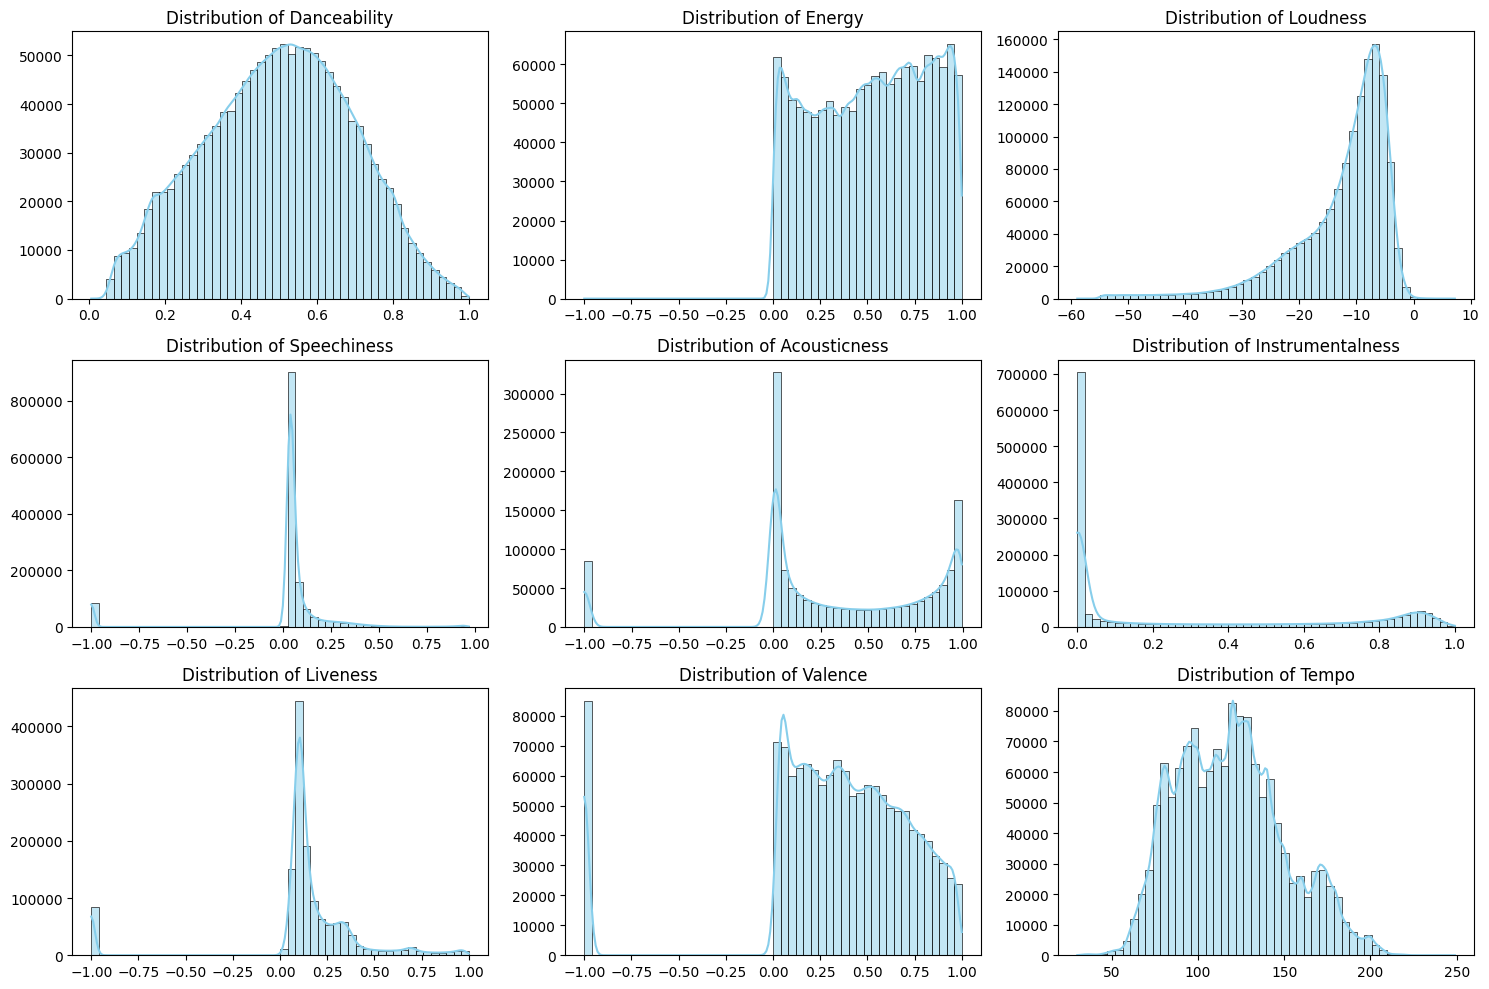

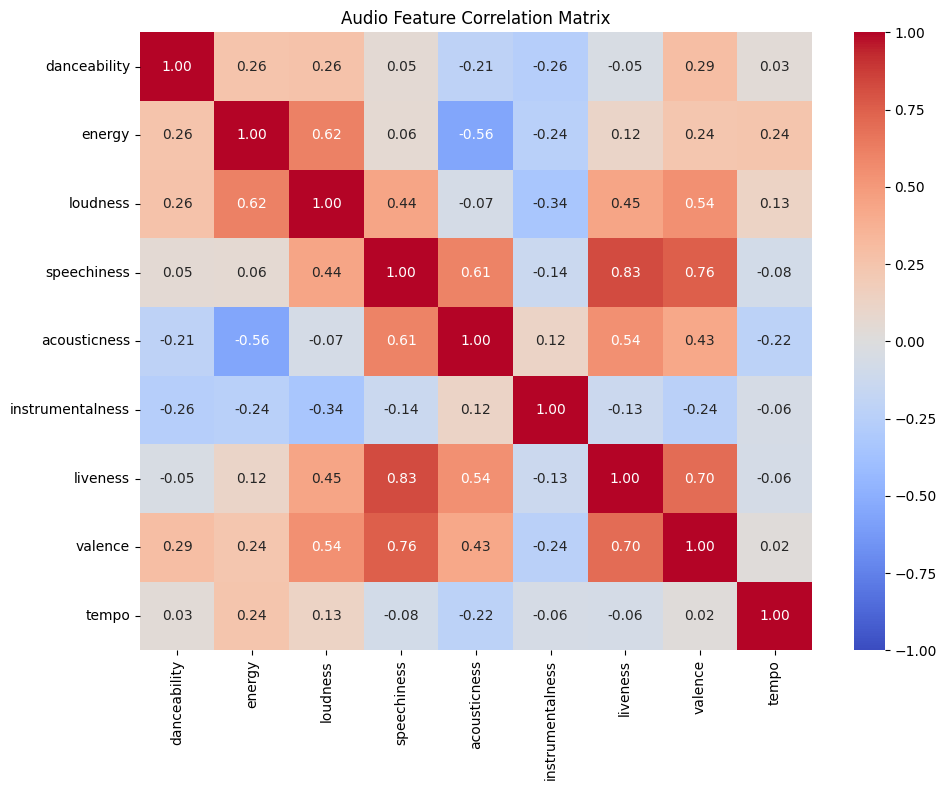

In [9]:
# --- Load and validate audio features ---

df = pd.read_csv(
    MASTER_DB,
    low_memory=False
)

features = [
    "danceability", "energy", "loudness",
    "speechiness", "acousticness",
    "instrumentalness", "liveness",
    "valence", "tempo"
]

valid_df = df.copy()

for col in features:
    valid_df[col] = pd.to_numeric(
        valid_df[col],
        errors="coerce"
    )

# Convert invalid values only where the ranges are known.
bounded = [
    "danceability", "energy", "speechiness",
    "acousticness", "instrumentalness",
    "liveness", "valence"
]

for col in bounded:
    valid_df.loc[
        ~valid_df[col].between(0, 1),
        col
    ] = np.nan

valid_df.loc[
    valid_df["tempo"] < 0,
    "tempo"
] = np.nan

print(f"Total tracks: {len(df)}")
print("\nFeature availability:")

print(
    (
        valid_df[features].notna().mean() * 100
    ).round(2)
)


# --- 2. Missing Values & Averages ---
print("\n--- Missing vs. Zero Values ---")
zero_counts = valid_df[features].eq(0.0).sum()
missing_counts = valid_df[features].isnull().sum()

summary_df = pd.DataFrame({
    'Missing (NaN)': missing_counts,
    'Exactly 0.0': zero_counts,
    'Percentage 0.0': (zero_counts / len(valid_df) * 100).round(2).astype(str) + '%'
})
print(summary_df)

# --- 3. Visualizing Distributions (Histograms) ---
print("\nGenerating Distribution Histograms...")
plt.figure(figsize=(15, 10))
for i, feature in enumerate(features, 1):
    plt.subplot(3, 3, i) # Creates a 3x3 grid of graphs
    sns.histplot(valid_df[feature], bins=50, kde=True, color='skyblue')
    plt.title(f'Distribution of {feature.capitalize()}')
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
#plt.savefig("feature_distributions.png")
#print("Saved histograms to 'feature_distributions.png'")

# --- 4. The Correlation Heatmap ---
print("\nGenerating Correlation Heatmap...")
plt.figure(figsize=(10, 8))
# Calculate how much every feature moves in relation to every other feature
correlation_matrix = valid_df[features].corr()

# Draw the heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Audio Feature Correlation Matrix")
plt.tight_layout()
#plt.savefig("feature_correlations.png")
#print("Saved heatmap to 'feature_correlations.png'")

In [5]:
def generate_causal_mask(seq_length):
    mask = torch.tril(torch.ones(seq_length, seq_length))
    mask = mask.masked_fill(mask == 0, float('-inf')).masked_fill(mask == 1, float(0.0))
    return mask


def pairwise_ranking_loss(pos_scores, neg_scores):
    """Encourage positive tracks to outrank negative tracks."""

    difference = pos_scores - neg_scores

    return -F.logsigmoid(difference).mean()


def apply_heuristics(base_scores, candidate_ids, metadata_tracker):
    """Apply lightweight preference and recency adjustments."""

    device = base_scores.device
    dtype = base_scores.dtype

    records = [
        metadata_tracker.get_metadata(track_id)
        for track_id in candidate_ids
    ]

    plays = torch.tensor(
        [r["play_count"] for r in records],
        dtype=dtype,
        device=device
    )

    skips = torch.tensor(
        [r["skip_count"] for r in records],
        dtype=dtype,
        device=device
    )

    # Use None to represent unknown library age.
    ages = [
        r["days_since_added"]
        for r in records
    ]

    recency_bonus = torch.tensor(
        [
            1.0 / (age + 1.0)
            if age is not None else 0.0
            for age in ages
        ],
        dtype=dtype,
        device=device
    )

    # Logarithmic penalties avoid excessive punishment
    # for tracks with long listening histories.
    fatigue_penalty = 0.05 * torch.log1p(plays)
    skip_penalty = 0.20 * torch.log1p(skips)

    adjusted_scores = (
        base_scores
        - fatigue_penalty
        - skip_penalty
        + recency_bonus
    )

    return adjusted_scores

In [6]:
def train_model(dataset, model, epochs=5, batch_size=32, learning_rate=0.001):
    if len(dataset) == 0:
        raise ValueError("Cannot train on an empty dataset.")

    device = next(model.parameters()).device

    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    causal_mask = generate_causal_mask(
        model.max_seq_length
    ).to(device)

    model.train()

    for epoch in range(epochs):
        total_loss = 0.0

        for batch in dataloader:
            (
                context_tensor,
                padding_mask,
                pos_features,
                neg_features
            ) = batch

            context_tensor = context_tensor.to(device)
            padding_mask = padding_mask.to(device)
            pos_features = pos_features.to(device)
            neg_features = neg_features.to(device)

            current_vibe = model(
                context_tensor,
                causal_mask,
                padding_mask
            )

            pos_scores = model.score_candidates(
                current_vibe,
                pos_features
            )

            neg_scores = model.score_candidates(
                current_vibe,
                neg_features
            )

            loss = pairwise_ranking_loss(
                pos_scores,
                neg_scores
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        average_loss = total_loss / len(dataloader)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Average Loss: {average_loss:.4f}"
        )


In [ ]:
EPOCHS = 5
BATCH_SIZE = 32
LEARNING_RATE = 0.001
MAX_SEQ_LENGTH = 10

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {DEVICE}")

nip_dataset = SpotifySequenceDataset(
    history_csv=HISTORY_DB,
    master_db_csv=MASTER_DB,
    max_seq_length=MAX_SEQ_LENGTH,
    mode="nip"
)

model = SpotifySASRec(
    num_features=NUM_FEATURES,
    d_model=128,
    max_seq_length=MAX_SEQ_LENGTH
).to(DEVICE)

train_model(
    dataset=nip_dataset,
    model=model,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE
)

Using device: cuda
Loading Master DB and processing features...
Feature availability:
  danceability: 99.8%
  energy: 100.0%
  key: 100.0%
  loudness: 100.0%
  mode: 100.0%
  speechiness: 93.8%
  acousticness: 93.8%
  instrumentalness: 100.0%
  liveness: 93.8%
  valence: 93.8%
  tempo: 99.8%
  time_signature: 93.6%
Built feature dictionary for 1374037 tracks.
Feature dimensions per track: 24


In [ ]:
def evaluate_hit_at_10(
    dataset,
    model,
    metadata_tracker=None,
    num_fakes=99,
    max_examples=500
):
    """Evaluate top-10 ranking against sampled negative tracks."""

    if dataset.mode != "nip":
        raise ValueError("Evaluation requires a NIP dataset.")

    if len(dataset) == 0:
        raise ValueError("Evaluation dataset is empty.")

    device = next(model.parameters()).device

    model.eval()

    hits = 0
    evaluated = 0

    candidate_pool = dataset.all_track_ids

    causal_mask = generate_causal_mask(
        model.max_seq_length
    ).to(device)

    with torch.no_grad():
        for i in range(min(max_examples, len(dataset))):
            (
                context_tensor,
                padding_mask,
                _,
                _
            ) = dataset[i]

            sample = dataset.data[i]

            true_track_id = sample["target"]

            excluded = set(sample["context"])
            excluded.add(true_track_id)

            available = [
                track_id
                for track_id in candidate_pool
                if track_id not in excluded
            ]

            negative_ids = random.sample(
                available,
                k=min(num_fakes, len(available))
            )

            candidates = [true_track_id] + negative_ids

            candidate_features = torch.stack([
                dataset.feature_lookup[track_id]
                for track_id in candidates
            ]).to(device)

            context_tensor = (
                context_tensor.unsqueeze(0).to(device)
            )

            padding_mask = (
                padding_mask.unsqueeze(0).to(device)
            )

            current_vibe = model(
                context_tensor,
                causal_mask,
                padding_mask
            )

            # Score all candidates against the context.
            target_vibes = model.feature_proj(
                candidate_features
            )

            raw_scores = (
                current_vibe.squeeze(0) * target_vibes
            ).sum(dim=-1)

            if metadata_tracker is not None:
                scores = apply_heuristics(
                    raw_scores,
                    candidates,
                    metadata_tracker
                )
            else:
                scores = raw_scores

            top_k = min(10, len(candidates))

            top_indices = torch.topk(
                scores,
                k=top_k
            ).indices

            if (top_indices == 0).any().item():
                hits += 1

            evaluated += 1

    hit_rate = 100.0 * hits / evaluated

    print(
        f"Hit@10: {hit_rate:.2f}% "
        f"({hits}/{evaluated})"
    )

    return hit_rate


--- Running Hit@10 Evaluation (1 True + 99 Fakes) ---
Hit@10 Score: 79.80%


In [ ]:

dpo_dataset = SpotifySequenceDataset(
    history_csv=HISTORY_DB,
    master_db_csv=MASTER_DB,
    max_seq_length=MAX_SEQ_LENGTH,
    mode="dpo"
)

DPO_EPOCHS = 3
DPO_LEARNING_RATE = 0.0001

print("--- Phase 2: Preference Fine-Tuning ---")

train_model(
    dataset=dpo_dataset,
    model=model,
    epochs=DPO_EPOCHS,
    batch_size=BATCH_SIZE,
    learning_rate=DPO_LEARNING_RATE
)

Loading Master DB and scaling features...
Converting to PyTorch tensors...
Success: Built dictionary for 1374037 tracks.
Divided 1823 tracks into 21 distinct listening sessions.
Extracted 1751 Next-Item (NIP) sequences.
Extracted 23 Preference (DPO) pairs.
Dataset initialized in DPO mode with 23 samples.

--- Phase 2: Fine-Tuning ---
Epoch 1 | Average Loss: 1.1205
Epoch 2 | Average Loss: 1.1962
Epoch 3 | Average Loss: 0.6208
--- Running Hit@10 Evaluation (1 True + 99 Fakes) ---
Hit@10 Score: 83.00% (Random chance is 10.00%)


In [ ]:
def isolate_missing_tracks(history_csv, master_db_csv, output_todo_csv):
    history_df = pd.read_csv(history_csv, low_memory=False)
    master_df = pd.read_csv(master_db_csv, low_memory=False)
    
    # 1. Get unique track IDs from both files
    history_tracks = set(history_df['track_id'].dropna())
    master_tracks = set(master_df['id'].dropna())
    
    # 2. Find the difference
    missing_ids = list(history_tracks - master_tracks)
    
    # 3. Create a clean To-Do list with artist/track names for the Spotify API
    missing_df = history_df[history_df['track_id'].isin(missing_ids)]
    missing_df = missing_df[['track_id', 'track_name', 'artist_name']].drop_duplicates()
    
    missing_df.to_csv(output_todo_csv, index=False)
    print(f"You have {len(missing_ids)} unique lifetime tracks missing from your Master DB.")
    print(f"Saved backlog to {output_todo_csv}")

isolate_missing_tracks(history_csv=HISTORY_DB, master_db_csv=MASTER_DB, output_todo_csv=DATA_DIR / "dsp_backlog.csv")

You have 6383 unique lifetime tracks missing from your Master DB.
Saved backlog to data/dsp_backlog.csv
